# APID 8 exploration

APID 8 has only 600 packets in the 14 dumps, but they are of six different kinds. The 24 byte ones look like the
APID 14 telecommand verification reports, so APID 8 is probably another command target. Questions:

1. What kinds of packets are there, and what do they have in common?
2. How do the commands, their reports and the data packets belong together?
3. What is in the 285 byte data packets?
4. Is any of it science data (SWAP, LYRA, DSLP, TPMU), or does it say anything about the Sun?

In [1]:
import itertools
from collections import Counter
from datetime import UTC, datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cadu import iter_packets, packet_apid, packet_sequence_count

In [2]:
CADU_DIR = Path("cadus")
APID = 8

GPS_EPOCH = datetime(1980, 1, 6, tzinfo=UTC)
GPS_MINUS_TICK = 1_209_613_891  # GPS seconds minus tick, from APID_0.ipynb / APID_18.ipynb
MAX_TICK = 400_000_000  # ticks above this are bit errors

# Packet layout (offsets into the whole packet, big-endian). Every kind has the PUS secondary header
# `10 <service> <subtype>`, the marker `00 01` and the tick (4 bytes) with its fraction (2 bytes).
SERVICE_OFFSET = 7
SUBTYPE_OFFSET = 8
MARKER = b"\x00\x01"
MARKER_OFFSET = 9
TIME_OFFSET = 11
FRACTION_OFFSET = 15
REQUEST_OFFSET = 18  # verification reports: packet id and sequence control of the telecommand
# Data packets (service 8): four zero bytes, a function code, a 4 byte length and that many data bytes.
FUNCTION_OFFSET = 21
LENGTH_OFFSET = 22
DATA_OFFSET = 26
CRC_LEN = 2

DATA_PACKET = (8, 0x85)
TELECOMMAND_ID = 0x1808  # version 0, type 1 (telecommand), secondary header, APID 8

## 1. Load

One pass over the 14 dumps keeps the APID 8 packets.

In [3]:
packets: list[tuple[str, int, bytes]] = []  # (file name, vcid, packet)
for path in sorted(CADU_DIR.glob("*.cadu")):
    packets += [(path.name, vcid, packet) for vcid, packet in iter_packets(path) if packet_apid(packet) == APID]
    print(f"processed {path.name}")

print(f"{len(packets)} packets with APID {APID}")
print("per file:", dict(Counter(name for name, _, _ in packets)))
print("per virtual channel:", dict(Counter(vcid for _, vcid, _ in packets)))

processed proba2_dump(1).cadu
processed proba2_dump(10).cadu


processed proba2_dump(11).cadu
processed proba2_dump(12).cadu
processed proba2_dump(2).cadu


processed proba2_dump(3).cadu
processed proba2_dump(4).cadu
processed proba2_dump(5).cadu


processed proba2_dump(6).cadu
processed proba2_dump(7).cadu
processed proba2_dump(8).cadu


processed proba2_dump(9).cadu
processed proba2_dump.cadu
processed proba2_dump_aug_12_eclipse.cadu
600 packets with APID 8
per file: {'proba2_dump(1).cadu': 25, 'proba2_dump(10).cadu': 10, 'proba2_dump(11).cadu': 33, 'proba2_dump(12).cadu': 24, 'proba2_dump(3).cadu': 33, 'proba2_dump(4).cadu': 39, 'proba2_dump(5).cadu': 18, 'proba2_dump(6).cadu': 62, 'proba2_dump(7).cadu': 18, 'proba2_dump(8).cadu': 33, 'proba2_dump(9).cadu': 18, 'proba2_dump.cadu': 286, 'proba2_dump_aug_12_eclipse.cadu': 1}
per virtual channel: {1: 569, 2: 31}


## 2. Packet kinds

In [4]:
def crc16(data: bytes) -> int:
    """CRC-16/CCITT-FALSE."""
    crc = 0xFFFF
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc


def crc_ok(packet: bytes) -> bool:
    return crc16(packet[:-CRC_LEN]) == int.from_bytes(packet[-CRC_LEN:])


def tick_of(packet: bytes) -> float:
    return int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]) + int.from_bytes(packet[FRACTION_OFFSET:][:2]) / 65536


def utc(tick: float) -> datetime:
    return GPS_EPOCH + timedelta(seconds=tick + GPS_MINUS_TICK)


print("packet id (version, type, secondary header flag, APID):", Counter(packet[:2].hex() for _, _, packet in packets))
print("sequence flags:", Counter(packet[2] >> 6 for _, _, packet in packets))
print(
    "length field is packet length - 7, among the CRC ok:",
    all(int.from_bytes(p[4:6]) == len(p) - 7 for _, _, p in packets if crc_ok(p)),
)
print()

census = Counter((len(packet), packet[6:9].hex(), crc_ok(packet)) for _, _, packet in packets)
print(f"{'length':>6s} {'sec. header':>11s} {'CRC ok':>6s} {'count':>5s}")
for (length, header, ok), count in sorted(census.items(), key=lambda item: -item[1]):
    print(f"{length:6d} {header:>11s} {ok!s:>6s} {count:5d}")

packet id (version, type, secondary header flag, APID): Counter({'0808': 597, '4008': 1, '2808': 1, 'e008': 1})
sequence flags: Counter({3: 599, 0: 1})
length field is packet length - 7, among the CRC ok: True

length sec. header CRC ok count
    24      100101   True   242
    24      100107   True   229
   285      100885   True    63
    26      100108   True    15
    41      100502   True    13
    32      100885   True    13
    33      100885   True     8
    20      101102   True     5
    24      100101  False     4
   285      100885  False     2
    20      101102  False     1
    24      100107  False     1
    41      100502  False     1
  1100      100101  False     1
    29      100885   True     1
   778      421008  False     1


The packet id is `0x0808` in 597 of the 600: version 0, secondary header, APID 8 (the other three are bit errors in the first byte, and fail the CRC). The secondary header is `10 <service> <subtype>`,
a PUS version byte, service and subtype, the same family as in APID 2, 14, 18, 21 and 22:

| Secondary header | PUS | Length | Meaning (by analogy with APID 14) |
|---|---|---|---|
| `10 01 01` | service 1, subtype 1 | 24 | telecommand accepted |
| `10 01 07` | service 1, subtype 7 | 24 | telecommand execution completed |
| `10 01 08` | service 1, subtype 8 | 26 | telecommand execution failed (has an error code) |
| `10 11 02` | service 17, subtype 2 | 20 | connection test report ("are you alive") |
| `10 05 02` | service 5, subtype 2 | 41 | event report |
| `10 08 85` | service 8, subtype 133 | 29, 32, 33, 285 | data; subtype 133 is APID 8's, APID 18, 21 and 22 use `89`, `8b` and `8e` |

The CRC-16/CCITT over the packet passes in 589 of the 600. The 11 that fail are a few reports and events and two 285 byte packets with bit
errors, and two long packets (778 and 1100 bytes) that are not real packets.

In [5]:
bad = [(name, vcid, packet) for name, vcid, packet in packets if not crc_ok(packet)]
print(f"{len(bad)} packets fail the CRC:")
for name, vcid, packet in bad:
    print(f"  {name:34s} vc {vcid} {len(packet):5d} bytes  {packet[:12].hex(' ')}")

11 packets fail the CRC:
  proba2_dump(10).cadu               vc 1    24 bytes  08 08 f3 27 00 11 10 01 01 00 01 0d
  proba2_dump(10).cadu               vc 1    20 bytes  08 08 f3 28 00 0d 10 11 02 00 16 ea
  proba2_dump(4).cadu                vc 1    24 bytes  08 08 ce 8d 00 11 10 01 01 00 01 0d
  proba2_dump(4).cadu                vc 1    24 bytes  40 08 ce 8e 00 11 10 01 07 00 01 0d
  proba2_dump(6).cadu                vc 2    41 bytes  08 08 c4 bd 00 22 10 05 02 c4 d6 9d
  proba2_dump(8).cadu                vc 1    24 bytes  08 08 fd 62 00 11 10 01 01 00 01 0d
  proba2_dump(8).cadu                vc 1   285 bytes  08 08 fd 63 01 16 10 08 85 00 01 0d
  proba2_dump.cadu                   vc 1  1100 bytes  08 08 c5 c0 38 11 10 01 01 00 01 0d
  proba2_dump.cadu                   vc 1    24 bytes  08 08 c7 0c 00 11 10 01 01 00 01 0d
  proba2_dump.cadu                   vc 1   285 bytes  28 08 c7 0d 01 16 10 08 85 00 01 0d
  proba2_dump_aug_12_eclipse.cadu    vc 2   778 bytes  e0 08 12 f

The 1100 byte packet is an ordinary report whose length field got corrupted (`0x3811` = 14 353 bytes): the demuxer kept appending frames to it, and
it swallowed the following reports (`0808c5c1...`) and more. The 778 byte one is in the eclipse dump (full of lost frames), has a corrupted packet id
(`e008`) and holds ASCII text, a GPS receiver message of APID 18 with its `10 08 89` header inside. Both are debris. Everything below uses
only the packets that pass the CRC.

In [6]:
good = [(name, vcid, packet) for name, vcid, packet in packets if crc_ok(packet) and tick_of(packet) < MAX_TICK]
frame = pd.DataFrame(
    {
        "file": [name for name, _, _ in good],
        "vc": [vcid for _, vcid, _ in good],
        "seq": [packet_sequence_count(packet) for _, _, packet in good],
        "tick": [tick_of(packet) for _, _, packet in good],
        "service": [packet[SERVICE_OFFSET] for _, _, packet in good],
        "subtype": [packet[SUBTYPE_OFFSET] for _, _, packet in good],
        "length": [len(packet) for _, _, packet in good],
        "packet": [packet for _, _, packet in good],
    }
)
frame["time"] = [utc(tick) for tick in frame["tick"]]
# the same packet can come on both virtual channels (real time and stored)
print(f"{len(frame)} good packets, {frame.duplicated(['file', 'seq']).sum()} seen twice")
frame = frame.drop_duplicates(["file", "seq"]).sort_values(["file", "seq"]).reset_index(drop=True)
print(frame.groupby(["service", "subtype", "length"]).size())

589 good packets, 0 seen twice
service  subtype  length
1        1        24        242
         7        24        229
         8        26         15
5        2        41         13
8        133      29          1
                  32         13
                  33          8
                  285        63
17       2        20          5
dtype: int64


## 3. Commands, reports and responses

### The sequence count is shared

The packet sequence count is one counter for the whole APID. In a stretch without lost frames it goes up by exactly one
per packet, whatever the kind. Here is the start of `proba2_dump(4).cadu`:

In [7]:
def request_count(packet: bytes) -> int:
    """The 14 bit sequence count of the telecommand a verification report is about."""
    return int.from_bytes(packet[REQUEST_OFFSET + 2 : REQUEST_OFFSET + 4]) & 0x3FFF


reports = frame[frame["service"] == 1]
print(
    "request packet ids:", Counter(int.from_bytes(p[REQUEST_OFFSET : REQUEST_OFFSET + 2]) for p in reports["packet"])
)
print("request sequence flags:", Counter(p[REQUEST_OFFSET + 2] >> 6 for p in reports["packet"]))


def timeline(name: str, count: int) -> None:
    rows = frame[frame["file"] == name].head(count)
    start = rows["tick"].iloc[0]
    for _, row in rows.iterrows():
        text = f"{row['service']}/{row['subtype']}"
        if row["service"] == 1:
            text += f" request {request_count(row['packet'])}"
        elif row["service"] == 8:
            text += f" function {row['packet'][FUNCTION_OFFSET]:#04x} {row['length']} bytes"
        print(f"  seq {row['seq']:5d}  +{row['tick'] - start:6.2f} s  {text}")


timeline("proba2_dump(4).cadu", 22)

request packet ids: Counter({6152: 486})
request sequence flags: Counter({3: 486})
  seq  3683  +  0.00 s  1/1 request 2495
  seq  3684  +  0.00 s  1/7 request 2495
  seq  3685  +  2.00 s  1/1 request 2496
  seq  3686  +  2.00 s  1/7 request 2496
  seq  3687  +  3.00 s  1/1 request 2494
  seq  3688  +  3.00 s  8/133 function 0x6a 285 bytes
  seq  3689  +  3.00 s  1/7 request 2494
  seq  3690  +  4.00 s  1/1 request 2497
  seq  3691  +  4.00 s  1/7 request 2497
  seq  3692  +  5.00 s  1/1 request 2494
  seq  3693  +  5.00 s  8/133 function 0x6a 285 bytes
  seq  3694  +  5.00 s  1/7 request 2494
  seq  3695  +  6.00 s  1/1 request 2498
  seq  3696  +  6.00 s  1/7 request 2498
  seq  3697  +  7.00 s  1/1 request 2494
  seq  3698  +  7.00 s  8/133 function 0x6a 285 bytes
  seq  3699  +  7.00 s  1/7 request 2494
  seq  3700  +  8.00 s  1/1 request 2499
  seq  3701  +  8.00 s  1/7 request 2499
  seq  3702  +  9.01 s  1/1 request 2494
  seq  3703  +  9.01 s  8/133 function 0x6a 285 bytes
  se

Every data packet sits between the *accepted* and the *completed* report of one telecommand: seq-1 is
`1/1`, seq+1 is `1/7`, and they quote the same request id. So the data packet is the response to that telecommand and the
three belong together. Request ids work as in APID 14: the telecommand packet id is `0x1808` (a telecommand to APID 8) in
every report, and the count is the sequence count of the telecommand.

In this stretch the telecommand 2494 comes every 2 s and is answered by a 285 byte packet every time, between
ground commands with the counts 2495, 2496, 2497... that get no data. So 2494 is a *poll*: the same command (the same
sequence count!) is executed again and again, which a real ground command would not do. It looks like a stored command
or a time-tagged schedule on board.

In [8]:
by_seq = {(row["file"], row["seq"]): row for _, row in frame.iterrows()}


def neighbours(row: pd.Series) -> tuple[int | None, int | None]:
    """Request counts of the reports just before (accepted) and just after (completed) a data packet."""
    before = by_seq.get((row["file"], row["seq"] - 1))
    after = by_seq.get((row["file"], row["seq"] + 1))
    return (
        request_count(before["packet"])
        if before is not None and (before["service"], before["subtype"]) == (1, 1)
        else None,
        request_count(after["packet"])
        if after is not None and (after["service"], after["subtype"]) == (1, 7)
        else None,
    )


data = frame[frame["service"] == 8].copy()
data["function"] = [packet[FUNCTION_OFFSET] for packet in data["packet"]]
data["accepted"], data["completed"] = zip(*(neighbours(row) for _, row in data.iterrows()), strict=True)
print(
    "data packets whose neighbours quote the same request:",
    int((data["accepted"] == data["completed"]).sum()),
    "of",
    len(data),
)
print()
print(
    data.groupby(["function", "length"])
    .agg(packets=("seq", "size"), requests=("accepted", "nunique"), first=("time", "min"), last=("time", "max"))
    .to_string()
)

data packets whose neighbours quote the same request: 85 of 85

                 packets  requests                            first                             last
function length                                                                                     
106      29            1         1 2025-10-10 04:00:48.246277+00:00 2025-10-10 04:00:48.246277+00:00
         33            8         8 2025-08-10 03:35:29.388306+00:00 2025-08-23 03:36:55.315430+00:00
         285          63         2 2025-08-21 17:19:52.661682+00:00 2025-10-10 04:00:47.240967+00:00
121      32           13        13 2025-08-08 03:41:00.484619+00:00 2025-08-23 03:36:17.322083+00:00


All 85 good data packets have both neighbours. The next table groups them by function code (byte 21, see below) and length:

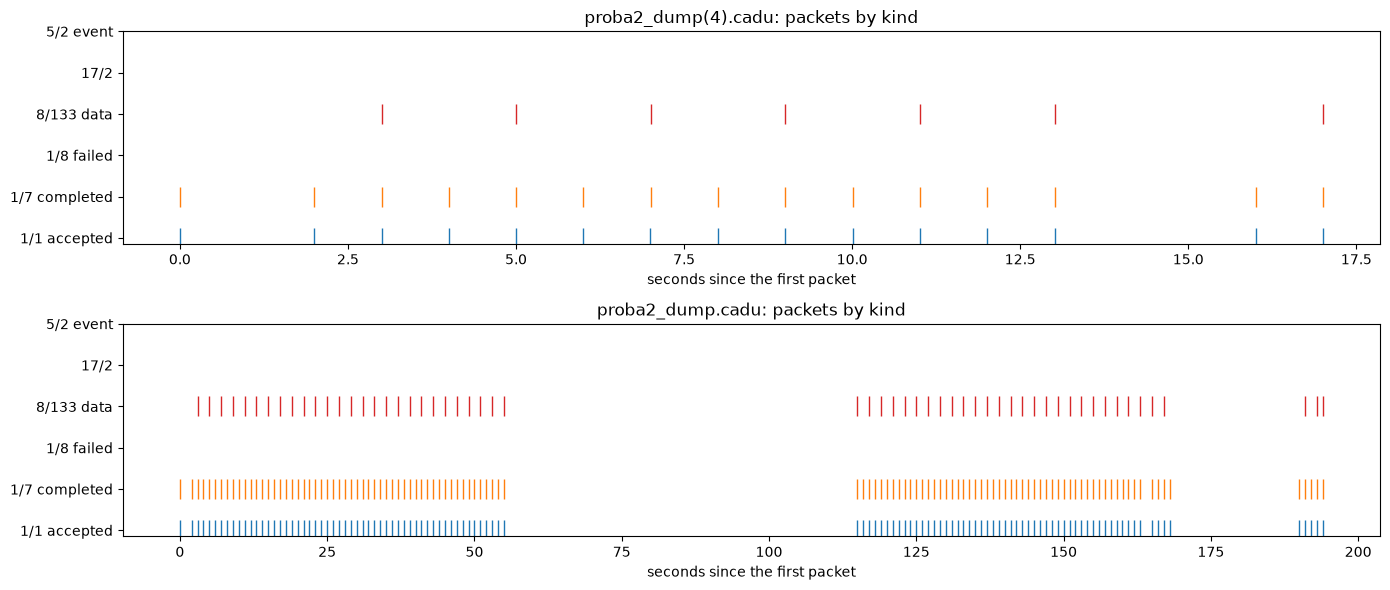

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6))
kinds = {
    (1, 1): "1/1 accepted",
    (1, 7): "1/7 completed",
    (1, 8): "1/8 failed",
    (8, 0x85): "8/133 data",
    (17, 2): "17/2",
    (5, 2): "5/2 event",
}
for ax, name in zip(axes, ["proba2_dump(4).cadu", "proba2_dump.cadu"], strict=True):
    rows = frame[frame["file"] == name]
    start = rows["tick"].min()
    for position, ((service, subtype), label) in enumerate(kinds.items()):
        sel = rows[(rows["service"] == service) & (rows["subtype"] == subtype)]
        ax.plot(sel["tick"] - start, [position] * len(sel), "|", markersize=14, label=label)
    ax.set(title=f"{name}: packets by kind", xlabel="seconds since the first packet")
    ax.set_yticks(range(len(kinds)), list(kinds.values()))
plt.tight_layout()
plt.show()

### The commands of every dump

In [10]:
print(f"{'file':34s} {'first accepted (UTC)':20s} {'commands':>8s} {'counts':>11s}  most repeated (count x times)")
accepted = reports[reports["subtype"] == 1].copy()
accepted["count"] = [request_count(packet) for packet in accepted["packet"]]
for name, rows in sorted(accepted.groupby("file"), key=lambda item: item[1]["tick"].min()):
    repeated = Counter(rows["count"]).most_common(1)[0]
    print(
        f"{name:34s} {rows['time'].min():%a %Y-%m-%d %H:%M:%S} {rows['count'].nunique():8d} "
        f"{rows['count'].min():5d}-{rows['count'].max():5d}  {repeated[0]} x {repeated[1]}"
    )

file                               first accepted (UTC) commands      counts  most repeated (count x times)
proba2_dump(12).cadu               Fri 2025-08-08 03:40:43       10  1168- 1179  1168 x 1
proba2_dump(11).cadu               Sun 2025-08-10 03:34:31       14  1426- 1448  1426 x 1
proba2_dump(10).cadu               Thu 2025-08-14 16:54:56        4  1737- 1740  1737 x 1
proba2_dump(9).cadu                Sat 2025-08-16 03:13:54        8  1863- 1871  1863 x 1
proba2_dump(8).cadu                Sun 2025-08-17 03:57:02       11  1986- 2009  1986 x 1
proba2_dump(7).cadu                Mon 2025-08-18 03:06:52        8  2215- 2222  2215 x 1
proba2_dump(6).cadu                Tue 2025-08-19 02:29:19       17  1634- 2358  2351 x 13
proba2_dump(5).cadu                Wed 2025-08-20 02:59:29        8  2346- 2353  2346 x 1
proba2_dump(4).cadu                Thu 2025-08-21 17:19:49        9  2494- 2503  2494 x 7
proba2_dump(3).cadu                Sat 2025-08-23 03:35:43       14  2679- 2702  

The counter of APID 8 is its own. In August it climbs by about 100 commands a day, from 1 168 (August 8) to 2 702 (August 23), with a small step back
between the dumps of August 19 and 20 (2 358, then 2 346), like the APID 14 counter. In October it is at 823-940: the counter went *back* by about 1 900 in
the weeks between the dumps, so it was reset (a 14 bit count would have taken 16 384 commands to wrap). The APID 14 counter does not do this
(2 981 to 5 738 over the same time, `APID_14.ipynb`). A restart of the on-board software is a guess.

The main dump `proba2_dump.cadu` repeats 839 56 times (57 with a report that fails the CRC), once per poll, and dump `proba2_dump(6)` repeats 2 351 13 times; those are the failed ones below. The
commands are mostly in the 02:30-04:00 UTC hours (all dumps except 1, 4 and 10), at 2 s to a minute from each other, which fits a ground contact pass.

The accepted and completed reports of a command should be close to each other in time:

In [11]:
accepted_by_key = {(row["file"], row["seq"]): row for _, row in reports[reports["subtype"] == 1].iterrows()}
latency = []
for (name, seq), row in accepted_by_key.items():
    for step in (1, 2):  # the completion follows directly, or after the data packet
        after = by_seq.get((name, seq + step))
        if (
            after is not None
            and (after["service"], after["subtype"]) == (1, 7)
            and request_count(after["packet"]) == request_count(row["packet"])
        ):
            latency.append(after["tick"] - row["tick"])
            break
latency = np.array(latency)
print(
    f"{len(latency)} commands with both reports, completion minus acceptance:"
    f" median {np.median(latency) * 1000:.2f} ms, "
    f"5 % to 95 %: {np.percentile(latency, 5) * 1000:.2f} to {np.percentile(latency, 95) * 1000:.2f} ms"
)

227 commands with both reports, completion minus acceptance: median 0.55 ms, 5 % to 95 %: 0.43 to 7.21 ms


Like in APID 14 the commands are executed within a millisecond or so: the median is 0.55 ms, and 95 % are within 7 ms.

### The function codes

In [12]:
print("bytes 17-20 of the data packets:", Counter(p[17:21].hex() for p in data["packet"]))
print("function codes:", Counter(f"{f:#04x}" for f in data["function"]))
print()
for _, row in data[data["length"] != 285].sort_values("tick").iterrows():
    packet = row["packet"]
    size = int.from_bytes(packet[LENGTH_OFFSET:DATA_OFFSET])
    payload = packet[DATA_OFFSET : DATA_OFFSET + size]
    request = row["accepted"] if row["accepted"] is not None else row["completed"]
    print(
        f"{row['file'][:20]:20s} {row['time']:%m-%d %H:%M:%S}  request {request}  "
        f"function {packet[FUNCTION_OFFSET]:#04x}  "
        f"length field {size}  packet {row['length']} bytes  data {payload.hex(' ')}"
    )

bytes 17-20 of the data packets: Counter({'00000000': 85})
function codes: Counter({'0x6a': 72, '0x79': 13})

proba2_dump(12).cadu 08-08 03:41:00  request 1170  function 0x79  length field 4  packet 32 bytes  data 00 00 00 00
proba2_dump(12).cadu 08-08 03:41:14  request 1171  function 0x79  length field 4  packet 32 bytes  data 00 00 00 00
proba2_dump(11).cadu 08-10 03:34:52  request 1428  function 0x79  length field 4  packet 32 bytes  data 00 00 00 00
proba2_dump(11).cadu 08-10 03:35:06  request 1429  function 0x79  length field 4  packet 32 bytes  data 00 00 00 00
proba2_dump(11).cadu 08-10 03:35:29  request 1433  function 0x6a  length field 5  packet 33 bytes  data 00 00 00 f0 00
proba2_dump(11).cadu 08-10 03:35:44  request 1435  function 0x6a  length field 5  packet 33 bytes  data 00 00 06 90 00
proba2_dump(9).cadu  08-16 03:14:29  request 1866  function 0x79  length field 4  packet 32 bytes  data 00 00 00 00
proba2_dump(8).cadu  08-17 03:57:02  request 1986  function 0x79  length

The layout of a data packet, offsets into the whole packet:

- **17-20:** zeros. **21:** function code, `0x6a` (106) or `0x79` (121). **22-25:** length of the data, as a 4 byte number. **26 to the last 2 bytes:**
  the data. **Last 2 bytes:** CRC-16.
- The length field is *exactly* the number of data bytes: 1 (the 29 byte packet), 4 (32 bytes), 5 (33 bytes) and 257 (285 bytes).
- `0x79` responses carry four zero bytes. `0x6a` responses carry a number followed by a `00` byte; in the 29 byte
  packet there is only the `00`. The 285 byte packets are `0x6a` as well, with 256 bytes of data and a final `00` at offset 282. So the
  last byte is a status or terminator (always `00` here), and the function code, length and data structure are
  those of a request/response protocol, read/write on some instrument interface that APID 8 forwards.
- The short responses come in pairs of commands: two `0x79` (four zero bytes) and, a few commands later, two `0x6a` reads (in the dumps 11, 3, 8 and 6).
  The numbers in the 33 byte responses are all multiples of 16 (0xf0, 0x690, 0x1710, 0x1d20, 0x4970, 0x55d0, 0x5ea0, 0x260). Within a pair
  they grow (0xf0 to 0x690, 0x1710 to 0x1d20, 0x4970 to 0x55d0) except in dump 6 (0x5ea0 to 0x260). They look like counters or addresses. `0x79` could be a command
  that sets something up and `0x6a` one that reads it back, but with 8 samples there is nothing to fit.
- The 29 byte response (`0x6a`, one data byte `00`) is the answer to the last command of the main dump (request 940, after the polling stopped).

### Failed commands

In [13]:
failed = frame[(frame["service"] == 1) & (frame["subtype"] == 8)]
print(len(failed), "reports 1/8, files:", dict(Counter(failed["file"])))
print("bytes 17 and 22-23:", Counter((p[17], p[22:24].hex()) for p in failed["packet"]))
print("requests:", Counter(request_count(p) for p in failed["packet"]))
print("seconds between the reports:", np.diff(failed["tick"].to_numpy()).round(1))

15 reports 1/8, files: {'proba2_dump(6).cadu': 15}
bytes 17 and 22-23: Counter({(0, '0050'): 15})
requests: Counter({2351: 13, 2352: 1, 2353: 1})
seconds between the reports: [2. 1. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]


The 15 reports of subtype 8 (all in `proba2_dump(6)`, 2025-08-19 03:53-03:54) say *completion failed*, with
the code `0x0050` (80) in 22-23. They are about the requests 2351 (13 times, one every 2 s like the poll in the other dumps), 2352 and 2353, and there is no
data packet. In APID 14 this subtype never occurs. Nothing in the downlink says why; the schedule kept sending the command, and the
15 reports come within 30 s of each other.

### Events and the connection test

In [14]:
events = frame[frame["service"] == 5]
for _, row in events.iterrows():
    packet = row["packet"]
    embedded = int.from_bytes(packet[32:36])
    print(
        f"{row['file'][:20]:20s} {row['time']:%a %m-%d %H:%M:%S}  tick {int(row['tick'])}  embedded tick {embedded}  "
        f"{packet[17:32].hex(' ')}"
    )
for name, group in events.groupby("file"):
    print(f"seconds between events in {name}:", np.diff(group["tick"].to_numpy()).round(0))
print()
for _, row in frame[frame["service"] == 17].iterrows():
    print(f"{row['file'][:20]:20s} {row['time']:%a %m-%d %H:%M:%S}  seq {row['seq']}  {row['packet'].hex(' ')}")

proba2_dump(1).cadu  Thu 10-09 13:40:10  tick 234438519  embedded tick 234438518  00 00 dc 04 5b 00 00 00 00 00 00 00 02 00 04
proba2_dump(1).cadu  Thu 10-09 13:58:16  tick 234439605  embedded tick 234439604  00 00 dc 04 5b 00 00 00 00 00 00 00 02 01 04
proba2_dump(1).cadu  Thu 10-09 14:16:22  tick 234440691  embedded tick 234440690  00 00 dc 04 5b 00 00 00 00 00 00 00 02 01 04
proba2_dump(1).cadu  Thu 10-09 14:34:28  tick 234441777  embedded tick 234441776  00 00 dc 04 5b 00 00 00 00 00 00 00 02 01 04
proba2_dump(1).cadu  Thu 10-09 15:16:05  tick 234444274  embedded tick 234444273  00 00 dc 04 5b 00 00 00 00 00 00 00 02 01 04
proba2_dump(1).cadu  Thu 10-09 15:34:11  tick 234445360  embedded tick 234445359  00 00 dc 04 5b 00 00 00 00 00 00 00 02 01 04
proba2_dump(1).cadu  Thu 10-09 15:52:17  tick 234446446  embedded tick 234446445  00 00 dc 04 5b 00 00 00 00 00 00 00 02 01 04
proba2_dump(1).cadu  Thu 10-09 16:10:23  tick 234447532  embedded tick 234447531  00 00 dc 04 5b 00 00 00 00 00

**Events (5/2).** Thirteen on virtual channel 2 (real time) in the dumps 1 (8) and 8 (5); the 14th, in dump 6, is garbage. Each has the same body, with a
copy of the tick at 32-35 (equal to the tick of the packet or one second less), `00 00 dc 04 5b` and the flag at offset 30 (`00` in the first event of dump 1, `01`
in all the others). They come every 1 086 s (18.1 min) like clockwork, with one longer step in dump 1 (2 497 s, not a multiple). In PUS (ECSS-E-70-41A)
service 5 subtype 2 is an anomaly report of low severity: the same condition over and over, not a measurement. Dump 1 has them on a Thursday from 13:40 to
16:10, and dump 8 on a Sunday from 02:33 to 03:46: nothing here follows the weekday TPMU window (14:01-16:33) from the README.

**17/2.** Five, in the dumps 12, 11, 9, 3 and 1, each with the first command of a burst: the report of a *connection test* (service 17 subtype 1), probably the first thing sent in a ground
contact. The body is just the tick and the fraction again, then `00`.

## 4. The 285 byte data packets

63 of them have a valid CRC, 56 in `proba2_dump.cadu` (2025-10-10 03:57-04:00) and 7 in `proba2_dump(4).cadu` (2025-08-21); two more, one
in the main dump and one in dump 8, have bit errors. They are the responses to the poll command (839 in the main dump, 2494 in dump 4) and come
every 2 s (with holes where frames were lost). After the 26 byte header there are 256 bytes of data and the final `00`.

### 16 byte records

A look at the hex dump: the bytes with `7d`, `3d`, `fd`, `8d` come back every 16 bytes, and all of them end in a `d`.

In [15]:
RECORD_LEN = 16
RECORDS = 16
STREAM_LEN = RECORD_LEN * RECORDS

polls = data[(data["length"] == 285)].sort_values(["file", "seq"]).reset_index(drop=True)
print(len(polls), "packets, files:", dict(Counter(polls["file"])))
print(
    "stream length is 256 + a final 00:",
    Counter(len(p) - DATA_OFFSET - CRC_LEN - STREAM_LEN for p in polls["packet"]),
    Counter(p[DATA_OFFSET + STREAM_LEN] for p in polls["packet"]),
)

rows = []
for _, row in polls.iterrows():
    packet = row["packet"]
    for index in range(RECORDS):
        record = packet[DATA_OFFSET + RECORD_LEN * index : DATA_OFFSET + RECORD_LEN * (index + 1)]
        rows.append((row["file"], row["tick"], row["seq"], index, record[0], int.from_bytes(record[1:4]), record[4:]))
records = pd.DataFrame(rows, columns=["file", "tick", "seq", "index", "tag", "stamp", "data"])
print(
    f"{len(records)} records, tags:",
    {f"{tag:#04x}": count for tag, count in sorted(Counter(records["tag"]).items(), key=lambda item: -item[1])},
)
print("low nibble of the tags:", Counter(records["tag"] & 0xF))

63 packets, files: {'proba2_dump(4).cadu': 7, 'proba2_dump.cadu': 56}
stream length is 256 + a final 00: Counter({1: 63}) Counter({0: 63})
1008 records, tags: {'0x4d': 350, '0x7d': 161, '0x3d': 161, '0xfd': 161, '0x8d': 161, '0x0d': 12, '0xcd': 1, '0x5d': 1}
low nibble of the tags: Counter({13: 1008})


The records are 16 bytes: **1 byte tag, 3 byte time stamp, 12 bytes of data.** Four tags make up almost all of them, in a fixed cycle
of four records, and a few other tags (`0x4d`, `0x0d`, a single `0xcd` and `0x5d`) appear in between.

In [16]:
SYNC_TAGS = [0x8D, 0x7D, 0x3D, 0xFD]
transitions = Counter()
for _, group in records.groupby("file"):
    tags = [tag for tag in group["tag"] if tag in SYNC_TAGS]
    transitions.update(itertools.pairwise(tags))
print("which of the 4 main tags follows which:")
for (before, after), count in sorted(transitions.items(), key=lambda item: -item[1]):
    print(f"  {before:#04x} -> {after:#04x}: {count}")

which of the 4 main tags follows which:
  0x7d -> 0x3d: 161
  0x3d -> 0xfd: 160
  0xfd -> 0x8d: 160
  0x8d -> 0x7d: 159
  0xfd -> 0xfd: 1
  0x3d -> 0x8d: 1


The cycle is `8d -> 7d -> 3d -> fd -> 8d`, across the packets as well (all but two of the 642 transitions; the two are damaged records). The next
packet carries on where the previous one stopped, in the middle of a cycle. So the data is a **continuous stream cut into packets** of 16 records,
and the packet boundary means nothing.

### The time stamp

The stamp is shared: `8d`, `7d` and `3d` of a cycle have the same stamp (the `fd` has its own, a few thousand units earlier). The stamps of
consecutive cycles are 3 600 units apart. A packet usually holds four cycles and the tick goes up by 2 s from one packet to the next, so
**the stamp counts at 7 200 Hz** and a cycle is 0.5 s.

In [17]:
by_stamp = (
    records[records["tag"].isin([0x8D, 0x7D, 0x3D])]
    .groupby(["file", "stamp"])["tag"]
    .apply(lambda tags: tuple(sorted(tags)))
)
print(
    "tags sharing a stamp:",
    {tuple(f"{t:#04x}" for t in key): count for key, count in Counter(by_stamp).most_common(4)},
)

cycles = records[records["tag"] == 0x7D]
for name, group in cycles.groupby("file"):
    steps = np.diff(group["stamp"].to_numpy())
    print(
        name,
        "steps between cycles:",
        dict(Counter(steps[abs(steps) < 10_000].tolist()).most_common(6)),
        " other steps:",
        steps[abs(steps) >= 10_000].tolist(),
    )

tags sharing a stamp: {('0x3d', '0x7d', '0x8d'): 159, ('0x3d', '0x7d'): 2, ('0x8d',): 2}
proba2_dump(4).cadu steps between cycles: {3600: 20, 3601: 4}  other steps: [14401]
proba2_dump.cadu steps between cycles: {3600: 114, 3601: 15, 3602: 2, 3603: 1}  other steps: [176406, -655228]


Within a run of consecutive packets the cycles are 3 600 units apart (3 601 to 3 603 now and then). There are three steps of other sizes: they sit
where frames were lost. The stamp has 24 bits, so it would wrap after 2 330 s, but the values stay between 11.9 and 16.3 million.

What does the stamp do against the tick? Per packet, the 7200 Hz time of its first stamped record (`8d`, `7d` or `3d`) minus the tick, relative to the start of a run of
packets that are 2 s apart (a lag of -2 s means the stream is 2 s behind where it was at the start of the run):

In [18]:
lag_rows = []
for name, group in polls.groupby("file"):
    previous_tick = None
    for _, row in group.sort_values("seq").iterrows():
        in_packet = records[(records["file"] == name) & (records["seq"] == row["seq"])]
        stamped = in_packet[in_packet["tag"].isin([0x8D, 0x7D, 0x3D])]  # these share the stamp of their cycle
        if stamped.empty:
            continue
        if previous_tick is None or row["tick"] - previous_tick > 2.5:
            origin = (stamped["stamp"].iloc[0], row["tick"], len(lag_rows))  # a new run: the lag is measured from here
        lag = (stamped["stamp"].iloc[0] - origin[0]) / 7200 - (row["tick"] - origin[1])
        lag_rows.append(
            (
                name,
                row["tick"],
                int((in_packet["tag"] == 0x7D).sum()),
                int((~in_packet["tag"].isin(SYNC_TAGS)).sum()),
                lag,
                origin[2],
            )
        )
        previous_tick = row["tick"]
lags = pd.DataFrame(lag_rows, columns=["file", "tick", "cycles", "extra", "lag", "run"])
print("run  packets  extra records so far  lag at the end (s)   -extra / 8 (s)")
for run, group in lags.groupby("run"):
    if len(group) < 4:
        continue
    extras_before = group["extra"].iloc[:-1].sum()
    print(f"{run:3d} {len(group):8d} {extras_before:21d} {group['lag'].iloc[-1]:19.2f} {-extras_before / 8:16.2f}")

run  packets  extra records so far  lag at the end (s)   -extra / 8 (s)
  0        6                     2               -0.01            -0.25
  7       27                    19               -2.50            -2.38
 34        7                     9               -1.00            -1.12


In a run the lag only ever goes **down**, and by what the extra records (section 5) explain: a packet always holds 16 records, so every extra
record pushes one cycle record out of the packet, and 4 extra records are a whole cycle (0.5 s), i.e. the lag is minus the number of extra records
so far divided by 8 (-2.50 against -2.38, -1.00 against -1.12; the stamps only have the granularity of a cycle). So the poll reads the next 256 bytes of a
**FIFO-like stream** at a fixed rate of 16 records per 2 s, while the stream is made at 4 records per 0.5 s *plus* the extra records, and the reading falls behind.
Between the runs the stamp does not follow the tick at all: after the two holes of lost frames it jumped by +25 s and by -90 s where the tick advanced
60 s and 24 s (after the second one the stream restarts about 4 s before the stamp where its first packet began). So the stamp measures time inside the
stream and says nothing about the date.

The four tags each carry 12 bytes of different kinds. Let's call them A (`7d`), B (`3d`), C (`fd`) and D (`8d`).

In [19]:
def byte_table(tag: int) -> pd.DataFrame:
    sel = records[records["tag"] == tag]
    table = {}
    for name, group in sel.groupby("file"):
        values = np.frombuffer(b"".join(group["data"]), dtype=np.uint8).reshape(-1, 12)
        table[name[:20]] = [
            f"{len(set(column.tolist()))} values, {Counter(column.tolist()).most_common(1)[0][0]:02x}"
            for column in values.T
        ]
    return pd.DataFrame(table, index=[f"byte {i}" for i in range(12)])


for tag, label in zip(SYNC_TAGS, "DABC", strict=True):
    print(f"== record {label} ({tag:#04x}), number of different values and the most common one:")
    print(byte_table(tag).to_string())

== record D (0x8d), number of different values and the most common one:
        proba2_dump(4).cadu proba2_dump.cadu
byte 0         1 values, 21     1 values, 21
byte 1         1 values, 6f     1 values, 6f
byte 2         3 values, b7     4 values, 97
byte 3         2 values, 33     3 values, 32
byte 4         1 values, 43     1 values, 43
byte 5         1 values, a0     1 values, a0
byte 6         2 values, 10     2 values, 10
byte 7         1 values, 08     2 values, 08
byte 8         1 values, 65     1 values, 65
byte 9         2 values, d1     3 values, d2
byte 10       10 values, 00    16 values, 90
byte 11        1 values, 08     2 values, 08
== record A (0x7d), number of different values and the most common one:
        proba2_dump(4).cadu proba2_dump.cadu
byte 0         1 values, f0     1 values, f0
byte 1         1 values, f3     4 values, f3
byte 2         2 values, 70     2 values, 50
byte 3         1 values, 03     1 values, 03
byte 4         2 values, 2c    10 values, a7
b

Most bytes are constant or take two to four values, and the constants are the same in August and October. A few bytes move: the lower bytes of the
counters in B and C, C's byte 6 (the staircase), D's byte 10 and A's bytes 4-7 (different values in the two dumps).

### Record C: a staircase

Bytes 5-6 of C are a 16 bit number around 0x8000 (offset binary). They take just ten values.

In [20]:
c_records = records[records["tag"] == 0xFD]
level = np.array([int.from_bytes(d[5:7]) - 0x8000 for d in c_records["data"]])
reading = np.array([d[3] for d in c_records["data"]])
print("levels:", sorted(Counter(level.tolist()).items()))
print("order (main dump):", level[c_records["file"].to_numpy() == "proba2_dump.cadu"][:40].tolist())
steps = (np.diff(level) % 500)[np.diff(c_records["stamp"].to_numpy()) < 10_000]
print("step between consecutive C records, modulo 500:", Counter(steps.tolist()).most_common(5))

print()
print("byte 3 (the one next to the staircase) at each level, per file:")
for name, group in c_records.groupby("file"):
    lvl = np.array([int.from_bytes(d[5:7]) - 0x8000 for d in group["data"]])
    byte3 = np.array([d[3] for d in group["data"]])
    print(
        f"  {name[:20]:20s}",
        {int(value): sorted(set(byte3[lvl == value].tolist())) for value in sorted(set(lvl.tolist()))},
    )

levels: [(0, 19), (50, 11), (100, 19), (150, 20), (200, 11), (250, 19), (300, 13), (350, 17), (400, 19), (450, 13)]
order (main dump): [150, 0, 350, 200, 50, 400, 250, 100, 400, 250, 100, 450, 300, 150, 0, 0, 350, 150, 0, 350, 200, 50, 400, 250, 100, 400, 250, 100, 450, 300, 150, 0, 350, 150, 0, 350, 200, 50, 400, 250]
step between consecutive C records, modulo 500: [(350, 137), (300, 18), (0, 1), (400, 1)]

byte 3 (the one next to the staircase) at each level, per file:
  proba2_dump(4).cadu  {0: [198], 50: [198], 100: [198], 150: [198], 200: [196], 250: [194], 300: [196], 350: [195], 400: [194], 450: [195]}
  proba2_dump.cadu     {0: [197], 50: [198], 100: [198], 150: [198], 200: [196], 250: [194], 300: [196], 350: [195], 400: [194], 450: [195]}


The ten levels are 0, 50, 100 ... 450 above 0x8000 and each C record is the **previous level + 350 (mod 500)**: 0, 350, 200, 50, 400, 250, 100, 450,
300, 150, 0 ... A staircase of ten steps of 50 counts, run through with a stride of 7 steps. That is what a 0.5 s sample of a fast sweep would look
like if it were aliased: a ramp whose period does not fit the sampling. (The stride is 300 instead of 350 in 18 of 157 steps, and I have no explanation for those.)

Byte 3 of the record is a function of the level, and the same function on 2025-08-21 and 2025-10-10: 198 at 50-150, 196 at 200, 194 at 250, 196 at 300,
195 at 350, 194 at 400, 195 at 450 (and 197 at level 0 in October, 198 in August). A value that repeats like this across 7 weeks is not a measurement
of the outside world. It reads like the response (the loopback) of a circuit to a stimulus the box generates itself, a self-test or calibration cycle.

The last four bytes of C (8-11) are a counter that goes up by 47 (sometimes 46) per C record.

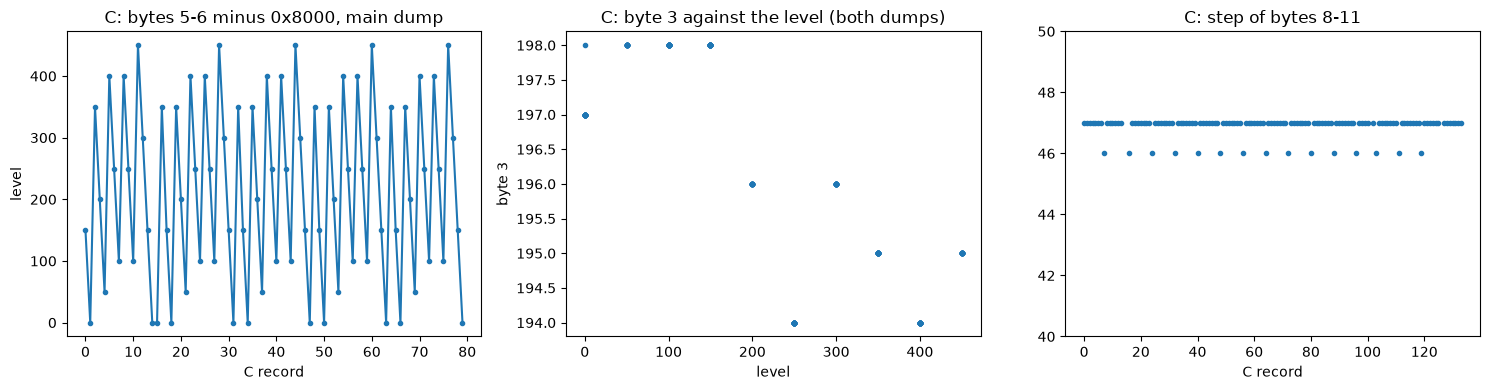

steps of the C counter: [(47, 115), (46, 15), (20, 1), (27, 1), (2344, 1)]


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
main = c_records[c_records["file"] == "proba2_dump.cadu"]
axes[0].plot([int.from_bytes(d[5:7]) - 0x8000 for d in main["data"]][:80], ".-")
axes[0].set(title="C: bytes 5-6 minus 0x8000, main dump", xlabel="C record", ylabel="level")
axes[1].plot(level, reading, ".")
axes[1].set(title="C: byte 3 against the level (both dumps)", xlabel="level", ylabel="byte 3")
counter = np.array([int.from_bytes(d[8:12]) for d in main["data"]])
axes[2].plot(np.diff(counter), ".")
axes[2].set(title="C: step of bytes 8-11", xlabel="C record", ylim=(40, 50))
plt.tight_layout()
plt.show()
print("steps of the C counter:", Counter(np.diff(counter).tolist()).most_common(5))

### Record B: a free-running counter

Bytes 8-11 of B (`04 1e 33 40`, `04 08 bb bc`, `04 13 44 38`...): the lowest 21 bits of this go up by a *constant*, which wraps around at 2^21.

In [22]:
b_records = records[records["tag"] == 0x3D]
for name, group in b_records.groupby("file"):
    counter = np.array([int.from_bytes(d[8:12]) for d in group["data"]])
    print(
        name[:20],
        "top byte:",
        Counter((counter >> 24).tolist()),
        " bits 21-23:",
        Counter(((counter >> 21) & 7).tolist()),
        " low 2 bits:",
        Counter((counter & 3).tolist()),
    )
    step = np.diff(counter & 0x1FFFFF) % 2**21
    print("   step modulo 2^21:", Counter(step.tolist()).most_common(4))
    slow = [int.from_bytes(d[4:8]) for d in group["data"]]
    print("   bytes 4-7:", Counter(f"{value:#x}" for value in slow).most_common(6))

proba2_dump(4).cadu top byte: Counter({4: 26})  bits 21-23: Counter({0: 26})  low 2 bits: Counter({0: 26})
   step modulo 2^21: [(690300, 22), (690064, 1), (690296, 1), (664052, 1)]
   bytes 4-7: [('0xcc', 16), ('0xce', 8), ('0xcf', 2)]
proba2_dump.cadu top byte: Counter({4: 135})  bits 21-23: Counter({0: 135})  low 2 bits: Counter({0: 135})
   step modulo 2^21: [(690300, 116), (690296, 6), (690060, 4), (690056, 2)]
   bytes 4-7: [('0x110', 36), ('0x111', 35), ('0x10b', 13), ('0x10c', 13), ('0x118', 13), ('0x117', 11)]


The top byte is always `04` and the low two bits are 0. The 21 bits below go up by the same amount in each B record, 690 300 per 0.5 s (a
few records are off by a few units), modulo 2^21 = 2 097 152. That is 1.38 million per second: a counter running at about 1.38 MHz that wraps every
1.5 s, or a faster counter that is *sampled* every 0.5 s and wraps many times in between. Either way it carries no more than a rate, and it is the same in August and
October (690 300 both times). Bytes 4-7 are a number that changes rarely (0xcc-0xcf in August, 0x10b-0x118 in October, one unit at a time).

### Records A and D, and the slow drift

A (`7d`) and D (`8d`) are constant but for the noise of a few bytes: D's byte 10 (the high nibble jumps around, 16 values) and bytes 2, 3 and 9
(one step of 16 or 1 up or down) look like the lowest bits of an ADC reading a constant. A's bytes 4-7 are different: they **rise slowly and
monotonically** in the main dump, each byte at its own pace.

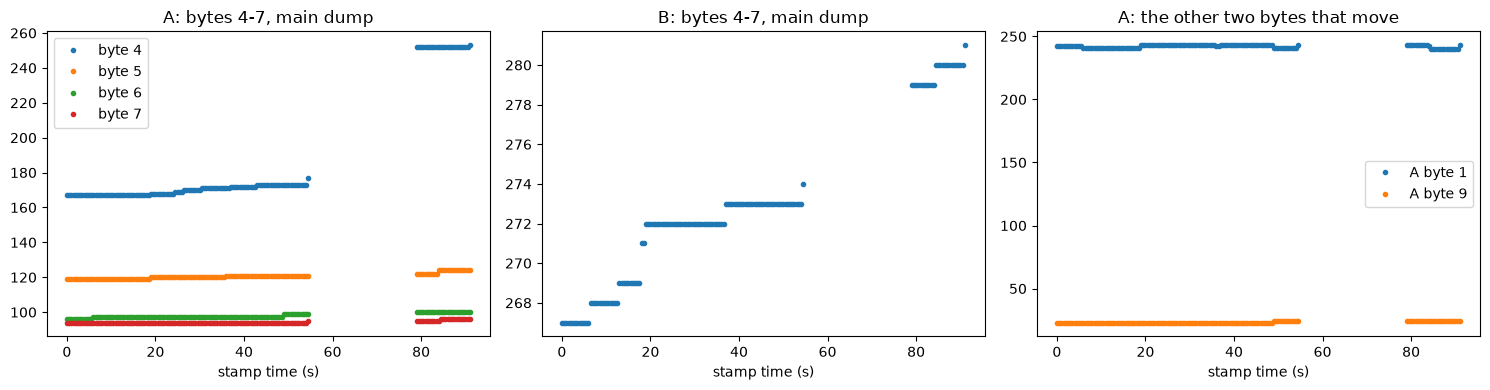

In [23]:
main_a = records[(records["file"] == "proba2_dump.cadu") & (records["tag"] == 0x7D)]
main_b = records[(records["file"] == "proba2_dump.cadu") & (records["tag"] == 0x3D)]
seconds_a = (main_a["stamp"].to_numpy() - main_a["stamp"].min()) / 7200
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for position in range(4, 8):
    axes[0].plot(seconds_a, [d[position] for d in main_a["data"]], ".", label=f"byte {position}")
axes[0].set(title="A: bytes 4-7, main dump", xlabel="stamp time (s)")
axes[0].legend()
axes[1].plot(
    (main_b["stamp"].to_numpy() - main_b["stamp"].min()) / 7200, [int.from_bytes(d[4:8]) for d in main_b["data"]], "."
)
axes[1].set(title="B: bytes 4-7, main dump", xlabel="stamp time (s)")
axes[2].plot(seconds_a, [d[1] for d in main_a["data"]], ".", label="A byte 1")
axes[2].plot(seconds_a, [d[9] for d in main_a["data"]], ".", label="A byte 9")
axes[2].set(title="A: the other two bytes that move", xlabel="stamp time (s)")
axes[2].legend()
plt.tight_layout()
plt.show()

Each of these bytes counts up by one every now and then, at its own pace (B's number goes from 267 to 281 in 90 s of stamp time, A's byte 4 from 167 to 173
in the first minute), with a jump where the stream has a hole. They are not a physical quantity one could name, since there is no unit. They could be slow
temperatures or voltages (a warming-up electronics box) as well as event counters.

## 5. The extra records: single bit flips

The records with the other tags appear between the cycles at irregular times: 350 with tag `0x4d`, 12 `0x0d`, one `0xcd` and one `0x5d`, in 38 of the 63 packets.

In [24]:
extra = records[~records["tag"].isin(SYNC_TAGS)].copy()


def deviation(data: bytes) -> list[int]:
    """Bits that differ from the 0x55 / 0xaa pattern in bytes 3-7 of the data (byte 2 tells which pattern)."""
    pattern = 0xAA if data[2] & 0x20 else 0x55
    return [(byte ^ pattern).bit_count() for byte in data[3:8]]


extra["deviation"] = [deviation(data) for data in extra["data"]]
print(len(extra), "extra records, tags", Counter(f"{tag:#04x}" for tag in extra["tag"]))
print("bits that differ from the pattern in bytes 3-7:", Counter(sum(d) for d in extra["deviation"]))
print("pattern byte 3:", Counter(f"{data[3]:#04x}" for data in extra["data"]).most_common(4))
print(
    "byte 2 bit 0x20 (pattern 0xaa) per tag:",
    Counter((f"{tag:#04x}", bool(data[2] & 0x20)) for tag, data in zip(extra["tag"], extra["data"], strict=True)),
)
print(
    "first byte of the address (data byte 8) per tag:",
    Counter((f"{tag:#04x}", f"{data[8]:#04x}") for tag, data in zip(extra["tag"], extra["data"], strict=True)),
)
print("packets with extra records:", extra[["file", "seq"]].drop_duplicates().shape[0], "of", len(polls))
print(
    "extra records per file:",
    extra.groupby("file").size().to_dict(),
    " packets per file:",
    polls.groupby("file").size().to_dict(),
)
print()
for _, row in extra[extra["deviation"].map(sum) != 1].iterrows():
    print("not a one bit flip:", f"{row['tag']:#04x}", row["file"], row["data"].hex(" "))
print()
for _, row in extra[extra["file"] == "proba2_dump.cadu"].head(14).iterrows():
    body = row["data"]
    parts = " | ".join(part.hex(" ") for part in (body[:3], body[3:8], body[8:]))
    print(f"{row['tag']:#04x} stamp {row['stamp']:9d}  {parts}  bits off: {sum(row['deviation'])}")

364 extra records, tags Counter({'0x4d': 350, '0x0d': 12, '0xcd': 1, '0x5d': 1})
bits that differ from the pattern in bytes 3-7: Counter({1: 362, 19: 1, 21: 1})
pattern byte 3: [('0xaa', 345), ('0x55', 17), ('0x6a', 1), ('0x04', 1)]
byte 2 bit 0x20 (pattern 0xaa) per tag: Counter({('0x4d', True): 342, ('0x0d', False): 9, ('0x4d', False): 8, ('0x0d', True): 3, ('0xcd', True): 1, ('0x5d', False): 1})
first byte of the address (data byte 8) per tag: Counter({('0x4d', '0x05'): 350, ('0x0d', '0x04'): 12, ('0xcd', '0x00'): 1, ('0x5d', '0x05'): 1})
packets with extra records: 38 of 63
extra records per file: {'proba2_dump(4).cadu': 8, 'proba2_dump.cadu': 356}  packets per file: {'proba2_dump(4).cadu': 7, 'proba2_dump.cadu': 56}

not a one bit flip: 0xcd proba2_dump.cadu e0 03 31 6a 00 00 00 01 00 00 00 00
not a one bit flip: 0x5d proba2_dump.cadu b0 fb 00 04 02 18 02 00 05 6f 88 e4

0x4d stamp  15707647  77 1e 51 | 55 55 55 51 55 | 05 23 b1 18  bits off: 1
0x0d stamp  15713356  01 0c 50 | 55 

Of the 364 extra records, 362 have the same shape (tag, then 12 bytes):

- **Bytes 3-7 of the data are the pattern `55 55 55 55 55` or `aa aa aa aa aa`, with exactly one bit different.** Bit 5 (0x20) of byte 2 tells which
  pattern (`5x` for 0x55, `7x` for 0xaa), and with that rule 362 of 364 records are a clean one bit deviation.
- **The last 4 bytes** are `05 xx xx xx` (all 350 `0x4d` records, which are mostly the 0xaa pattern) or `04 xx xx xx` (all 12 `0x0d` records, mostly 0x55), with the
  low two bits 0: they look like a 32 bit *address* of a word in two ranges.
- **The first two bytes** count in a packed way. In `0x4d` records the high nibble of byte 0 goes up by one per record (77, 78, 88, 98, a8, b8, b9, c9, d9...)
  while the other three nibbles move now and then (as if there were four independent 4 bit counters). In `0x0d` records byte 0 is `01` and byte 1 a plain counter (0c, 0d, 0e, 0f, 10, 11, 12).

The odd two: `0xcd` (`e0 03 31 6a 00 00 00 01 00 00 00 00`) has `6a 00 00 00 01 00` in the middle, the layout of the 29 byte response (function `0x6a`,
length 1, data `00`): a response embedded in the stream. The `0x5d` record (`b0 fb 00 04 02 18 02 00 05 6f 88 e4`) looks like a mix of a record A and an address, probably a damaged record.

Alternating `0x55` / `0xAA` is the classic pattern to fill a memory for a test, and a changed bit with the address of the word is what a memory
checker would log. So the best reading is a **memory test log: words that differ from the 0x55 / 0xaa fill, with their address**. It is not a
log of random single event upsets, because 326 of the 362 flips are the *same bit* (the third byte of the five, bit 5), almost all in three big groups
of 225, 66 and 33 records with **one stamp each**. In the largest the addresses **strictly increase** (steps of 32 or 64 bytes mostly): it reads like a scan of a memory
region that reports every word with that one wrong bit, which would fit a stuck or weak cell and not cosmic rays. The other 36 flips are spread over many bits and addresses (26 of them alone at their stamp), and those could be real upsets. All the records of a group share one stamp, so the stamp is probably the time the log was written and not the time of the flips. The big groups fill the packets and
push out the cycles, which is why the main dump has 356 extra records and the lag grows.

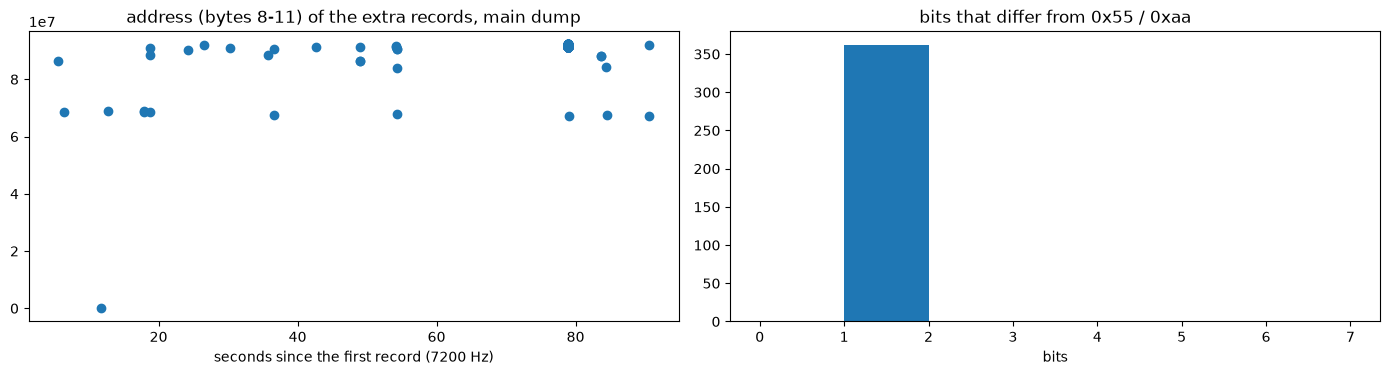

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
main_extra = extra[extra["file"] == "proba2_dump.cadu"]
axes[0].plot(
    (main_extra["stamp"] - records[records["file"] == "proba2_dump.cadu"]["stamp"].min()) / 7200,
    [int.from_bytes(d[8:]) for d in main_extra["data"]],
    "o",
)
axes[0].set(
    title="address (bytes 8-11) of the extra records, main dump", xlabel="seconds since the first record (7200 Hz)"
)
axes[1].hist([sum(d) for d in extra["deviation"]], bins=range(0, 8))
axes[1].set(title="bits that differ from 0x55 / 0xaa", xlabel="bits")
plt.tight_layout()
plt.show()

### Where the flipped bits are

In [26]:
flips = extra[extra["deviation"].map(sum) == 1].copy()
flips["address"] = [int.from_bytes(data[8:12]) for data in flips["data"]]


def flipped_bit(data: bytes) -> tuple[int, int]:
    """(byte of the pattern, bit) that is wrong."""
    pattern = 0xAA if data[2] & 0x20 else 0x55
    position = next(i for i, byte in enumerate(data[3:8]) if byte != pattern)
    return position, (data[3 + position] ^ pattern).bit_length() - 1


flips["bit"] = [flipped_bit(data) for data in flips["data"]]
print("low 2 bits of the address:", Counter((flips["address"] & 3).tolist()))
print(
    "which bit is wrong (byte of the five, bit):",
    sorted(Counter(flips["bit"]).items(), key=lambda item: -item[1])[:12],
)
sizes = flips.groupby(["file", "stamp"]).size()
print("records sharing one stamp, size of the groups:", sorted(Counter(sizes).items()))
largest = flips.set_index(["file", "stamp"]).loc[sizes.idxmax()]
steps = np.diff(largest["address"].to_numpy())
low, high = largest["address"].min(), largest["address"].max()
print(f"the largest group ({len(largest)} records): addresses {low:#x} to {high:#x}")
print("   steps between them:", dict(Counter(steps.tolist()).most_common(6)))
print("bits wrong in that group:", Counter(largest["bit"]))
print("addresses are", "increasing" if (steps > 0).all() else "not monotonic", "in it")

low 2 bits of the address: Counter({0: 362})
which bit is wrong (byte of the five, bit): [((2, 5), 326), ((4, 6), 7), ((3, 3), 7), ((1, 0), 3), ((3, 7), 3), ((1, 2), 3), ((1, 1), 2), ((3, 1), 2), ((3, 2), 1), ((3, 6), 1), ((4, 7), 1), ((4, 4), 1)]
records sharing one stamp, size of the groups: [(1, 26), (2, 3), (6, 1), (33, 1), (66, 1), (225, 1)]
the largest group (225 records): addresses 0x5711a60 to 0x57b6fc0
   steps between them: {64: 154, 32: 29, 736: 7, 608: 7, 96: 6, 2784: 4}
bits wrong in that group: Counter({(2, 5): 225})
addresses are increasing in it


## 6. When is the data, and is it TPMU/DSLP?

In [27]:
for name, group in polls.groupby("file"):
    first, last = group["time"].min(), group["time"].max()
    print(f"{name:34s} {len(group):3d} packets  {first:%a %Y-%m-%d %H:%M:%S} to {last:%H:%M:%S} UTC")
print()
print("all data packets, by weekday:", dict(Counter(f"{time:%a}" for time in data["time"])))

proba2_dump(4).cadu                  7 packets  Thu 2025-08-21 17:19:52 to 17:20:06 UTC
proba2_dump.cadu                    56 packets  Fri 2025-10-10 03:57:37 to 04:00:47 UTC

all data packets, by weekday: {'Sun': 7, 'Fri': 59, 'Sat': 5, 'Thu': 7, 'Wed': 2, 'Tue': 3, 'Mon': 2}


The poll data is from Thursday 2025-08-21 17:19-17:20 and Friday 2025-10-10 03:57-04:00. The shorter responses (`0x79`/`0x6a`) are in 8 more dumps, all
between 02:59 and 03:57 UTC, on any day of the week, with Saturdays and Sundays as well. TPMU is expected on weekdays only, from about 14:00 to 16:33 UTC,
and nothing in APID 8 shows that rhythm: the commands are at the time of the ground contact, and the 5/2 events of dump 8 are on a Sunday at 02:33-03:46.
So nothing in the timing supports DSLP or TPMU, and the content of the polled stream does not look like plasma measurements either (see section 4).

## 7. What we know so far

* APID 8 is a **command and response channel** of some on-board unit: 600 packets of 6 kinds, all with a PUS secondary header `10 <service> <subtype>`:
  telecommand verification (service 1: 1/1 accepted, 1/7 completed, 1/8 failed with the code `0x0050`), connection test reports (17/2), anomaly events (5/2, every 1 086 s,
  always the same body) and data (8/133). 589 of the 600 pass the CRC-16.
* **The telecommands are sent to APID 8** (request packet id `0x1808`) and counted by their own 14 bit counter: 1 168 to 2 702 in August
  (about 100 a day), 823 to 940 in October, so it was reset between the dumps. The sequence count of the packets is one counter for the APID, and **a data packet sits between
  the accepted and the completed report of the command that asked for it** (85 of 85).
* A data packet is: four zero bytes, a function code (`0x6a` or `0x79`), a 4 byte length that is exactly the number of data bytes, the data, a CRC.
  The responses are 1, 4, 5 or 257 bytes long. `0x79` returns four zero bytes, `0x6a` a number that is a multiple of 16 (5 byte answers), or the 256 byte stream.
* One command is a **poll that is executed again and again every 2 s with the same sequence count** (839 on 2025-10-10, 2494 on 2025-08-21): it looks like a
  stored command or schedule on board and not like a ground command. Each poll returns the next 256 bytes of a **continuous stream** of 16 byte records
  (tag, 24 bit stamp at 7 200 Hz, 12 bytes). It behaves like a FIFO that is read at a fixed 16 records per 2 s, so that its stamps fall behind the tick as soon as extra records fill it.
* The stream has a **cycle of four records every 0.5 s** (A `7d`, B `3d`, C `fd`, D `8d`): a free-running counter that is the same in August and October (B), a **ten
  step staircase with stride 350 mod 500** and a reading that depends on the step only (C), slow rising counters (A, B) and a few noisy bytes (D). The
  repetition of the same values 7 weeks apart says it is not a measurement of the outside world: a self test or a stimulus/loopback cycle.
* Between the cycles come **memory test records**: a `0x55`/`0xaa` pattern with one wrong bit and a 32 bit address. 326 of 362 are the same bit, almost all in three bursts (the largest with ascending addresses).
* Nothing about the Sun, the SWAP pixel offsets or the attitude. Not LYRA (APID 21). The timing and the content do not point to DSLP or TPMU.

Still open: what the function codes `0x6a` and `0x79` are, why the 5 byte responses are multiples of 16, which unit has a 7 200 Hz clock, a staircase of ten levels and a memory with a
0x55/0xaa fill (a star tracker, the on-board computer, a payload computer?), what the error code `0x0050` means, why the stamp jumps back 90 s after a hole,
and what the periodic 5/2 event (every 1 086 s) is.